# Definitions

In [2]:
import os
import json
import yaml
import numpy as np
import librosa
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
import seaborn as sns
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix

In [3]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """
    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title('Instrument frequency in MedleyDB')
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

In [4]:
# First, we define the mapping we already agreed on
# Mapping from original instruments to grouped categories
instrument_mapping = {
    # Large individual classes
    'electric_bass': 'electric_bass',
    'drum_set': 'drum_set',
    'piano': 'piano',
    'tack_piano': 'piano',
    'synthesizer': 'synthesizer',
    'electric_piano': 'synthesizer',
    'clean_electric_guitar': 'clean_electric_guitar',
    'distorted_electric_guitar': 'distorted_electric_guitar',
    'acoustic_guitar': 'acoustic_guitar',
    'violin': 'violin',
    'female_singer': 'female_singer',
    'vocalists': 'vocalists',
    
    # Male vocals
    'male_singer': 'male_vocals',
    'male_speaker': 'male_vocals',
    'male_rapper': 'male_vocals',
    
    # Other bowed strings
    'viola': 'other_bowed_strings',
    'cello': 'other_bowed_strings',
    'double_bass': 'other_bowed_strings',
    'violin_section': 'other_bowed_strings',
    'viola_section': 'other_bowed_strings',
    'cello_section': 'other_bowed_strings',
    'string_section': 'other_bowed_strings',
    'erhu': 'other_bowed_strings',
    
    # Woodwinds
    'flute': 'woodwinds',
    'clarinet': 'woodwinds',
    'oboe': 'woodwinds',
    'bassoon': 'woodwinds',
    'tenor_saxophone': 'woodwinds',
    'soprano_saxophone': 'woodwinds',
    'alto_saxophone': 'woodwinds',
    'baritone_saxophone': 'woodwinds',
    'bass_clarinet': 'woodwinds',
    'piccolo': 'woodwinds',
    'flute_section': 'woodwinds',
    'clarinet_section': 'woodwinds',
    
    # Brass
    'trumpet': 'brass',
    'trombone': 'brass',
    'french_horn': 'brass',
    'french_horn_section': 'brass',
    'brass_section': 'brass',
    'tuba': 'brass',
    'horn_section': 'brass',
    'trumpet_section': 'brass',
    
    # Other percussion
    'auxiliary_percussion': 'other_percussion',
    'tambourine': 'other_percussion',
    'cymbals': 'other_percussion',
    'timpani': 'other_percussion',
    'tabla': 'other_percussion',
    'shaker': 'other_percussion',
    'snare_drum': 'other_percussion',
    'bass_drum': 'other_percussion',
    'kick_drum': 'other_percussion',
    'bongo': 'other_percussion',
    'darbuka': 'other_percussion',
    'doumbek': 'other_percussion',
    'gong': 'other_percussion',
    'toms': 'other_percussion',
    'drum_machine': 'other_percussion',
    'claps': 'other_percussion',
    'chimes': 'other_percussion',
    
    # Other plucked strings
    'mandolin': 'other_plucked_strings',
    'banjo': 'other_plucked_strings',
    'guzheng': 'other_plucked_strings',
    'oud': 'other_plucked_strings',
    'harp': 'other_plucked_strings',
    'lap_steel_guitar': 'other_plucked_strings',
    'yangqin': 'other_plucked_strings',
    'zhongruan': 'other_plucked_strings',
    'glockenspiel': 'other_plucked_strings',
    'vibraphone': 'other_plucked_strings',
    
    # Reed instruments
    'accordion': 'reed_instruments',
    'harmonica': 'reed_instruments',
    'melodica': 'reed_instruments',
    
    # Effects and processed sounds
    'fx_slash_processed_sound': 'fx_and_processed',
    'scratches': 'fx_and_processed'
}

# List of instruments to completely discard
instruments_to_discard = [
    'sampler',
    'main_system',
    'trombone_section',
]

# Final categories
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

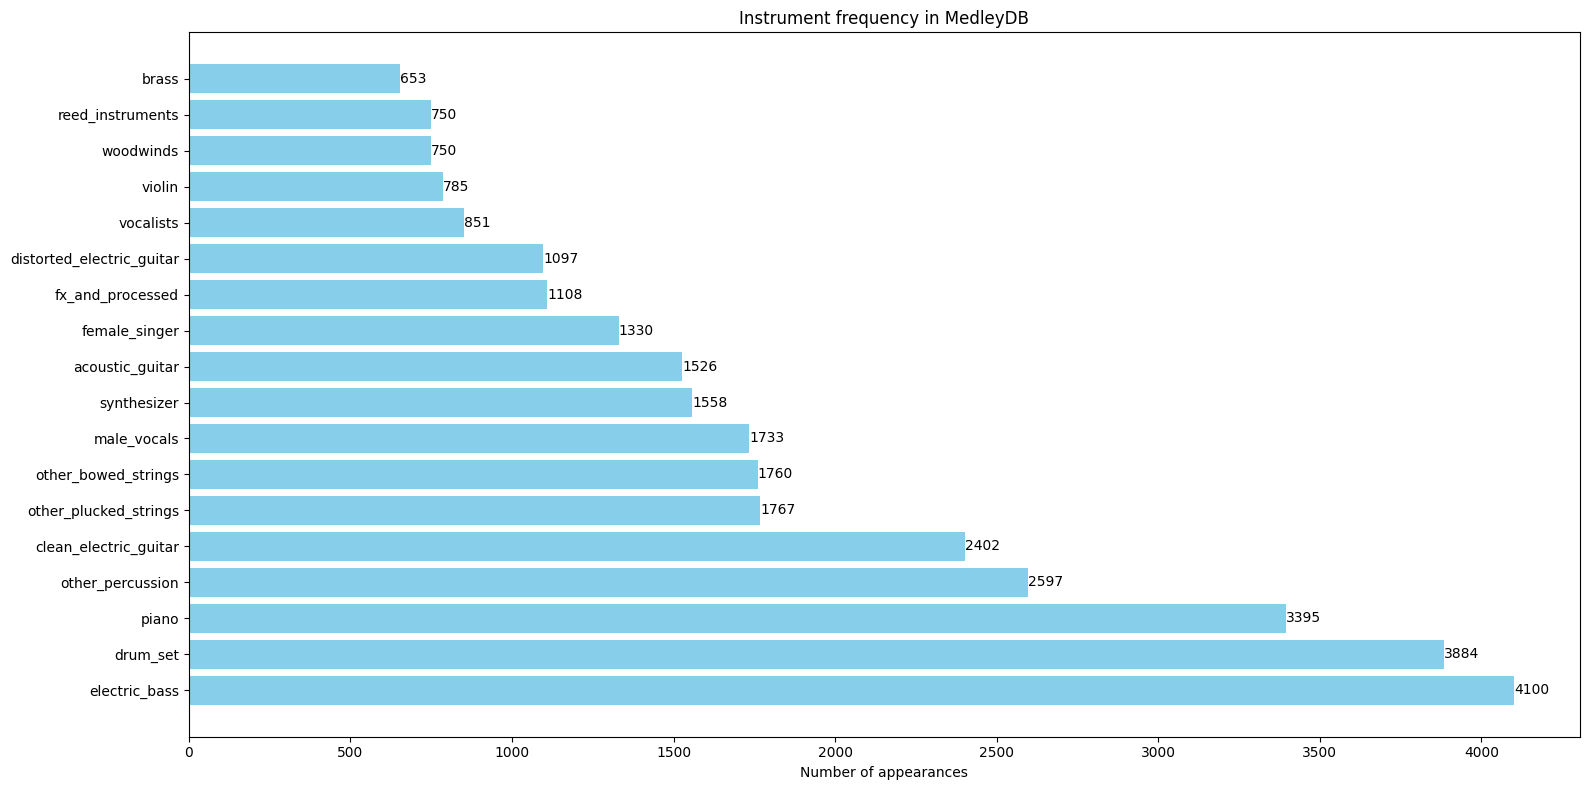

In [5]:
# 1️⃣ Load the features
mel_features = np.load("extracted_mix_features/all_mels.npy")
cqt_features = np.load("extracted_mix_features/all_cqts.npy")
labels = np.load("extracted_mix_features/all_labels.npy")


'''
# 🟡 Conversione in float32 e rimozione dimensioni inutili
X_mel = np.stack([np.squeeze(f).astype(np.float32) for f in mel_features])  # (batch, 96, 259)
X_cqt = np.stack([np.squeeze(f).astype(np.float32) for f in cqt_features])  # (batch, 96, 259)
y = np.stack([l.astype(np.float32) for l in labels])                        # (batch, num_labels)
'''
class_counts = np.sum(labels, axis=0)

# Crear diccionario {nombre_categoria: cantidad}
category_counts = {label: int(count) for label, count in zip(instrument_categories, class_counts)}


plot_instrument_histogram(category_counts, top_n=np.shape(labels)[1])

In [6]:
np.shape(labels)[1]

18

In [7]:
print(f"  Full data: {mel_features.shape}")

  Full data: (9154, 96, 130)


In [8]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    cqt_features, labels, test_size=0.1, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

print(f"Loaded data: {cqt_features.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

Loaded data: (9154, 96, 130)


# Model 1: not appliable to hybrid

In [ ]:
# 🔵 Definizione CNN 2D
def create_cnn_model(input_shape, num_labels):
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(128, (3,3), activation='relu'),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_labels, activation='sigmoid')  # multilabel output
    ])
    return model

# 🔵 Crea e compila modello
#input_shape = X_train.shape[1:]  
input_shape = (X_train.shape[1], X_train.shape[2], 1)
num_labels = y_train.shape[1]

model = create_cnn_model(input_shape, num_labels)
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 94, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 29, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         1,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,098 (398.82 KB)

 Trainable params: 102,098 (398.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Callbacks for training
csv_logger = CSVLogger('training_model_mix.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=20)

model_name = 'best_model_mix.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - binary_accuracy: 0.7806 - loss: 0.4738
Epoch 1: val_binary_accuracy improved from -inf to 0.82107, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 13s 55ms/step - binary_accuracy: 0.7809 - loss: 0.4734 - val_binary_accuracy: 0.8211 - val_loss: 0.4113
Epoch 2/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.8253 - loss: 0.3983
Epoch 2: val_binary_accuracy improved from 0.82107 to 0.83002, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - binary_accuracy: 0.8253 - loss: 0.3982 - val_binary_accuracy: 0.8300 - val_loss: 0.3850
Epoch 3/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.8392 - loss: 0.3706
Epoch 3: val_binary_accuracy improved from 0.83002 to 0.84450, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - binary_accuracy: 0.8392 - loss: 0.3705 - val_binary_accuracy: 0.8445 - val_loss: 0.3641
Epoch 4/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - binary_accuracy: 0.8517 - loss: 0.3504
Epoch 4: val_binary_accuracy improved from 0.84450 to 0.85191, saving model to best_model_mix.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - binary_accuracy: 0.8517 - loss: 0.3504 - val_binary_accuracy: 0.8519 - val_loss: 0.3511
Epoch 5/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - binary_accuracy: 0.8598 - loss: 0.3305
Epoch 5: val_binary_accuracy improved from 0.85191 to 0.85518, saving model to best_model_mix.h5


...

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9762 - loss: 0.0635 - val_binary_accuracy: 0.9612 - val_loss: 0.1144
Epoch 102/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9783 - loss: 0.0608
Epoch 102: val_binary_accuracy did not improve from 0.96124
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9783 - loss: 0.0608 - val_binary_accuracy: 0.9581 - val_loss: 0.1235
Epoch 103/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9759 - loss: 0.0648
Epoch 103: val_binary_accuracy did not improve from 0.96124
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9759 - loss: 0.0648 - val_binary_accuracy: 0.9601 - val_loss: 0.1114
Epoch 104/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9777 - loss: 0.0614
Epoch 104: val_binary_accuracy did not improve from 0.96124
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9777 - loss: 0.0614 - val_binary_accuracy: 0.9604 - val_loss: 0.11

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9800 - loss: 0.0543 - val_binary_accuracy: 0.9637 - val_loss: 0.1109
Epoch 112/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9795 - loss: 0.0547
Epoch 112: val_binary_accuracy did not improve from 0.96375
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9795 - loss: 0.0547 - val_binary_accuracy: 0.9634 - val_loss: 0.1109
Epoch 113/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9806 - loss: 0.0523
Epoch 113: val_binary_accuracy did not improve from 0.96375
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9806 - loss: 0.0523 - val_binary_accuracy: 0.9629 - val_loss: 0.1111
Epoch 114/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9804 - loss: 0.0538
Epoch 114: val_binary_accuracy did not improve from 0.96375
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9804 - loss: 0.0538 - val_binary_accuracy: 0.9635 - val_loss: 0.10

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9813 - loss: 0.0514 - val_binary_accuracy: 0.9665 - val_loss: 0.1068
Epoch 127/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - binary_accuracy: 0.9836 - loss: 0.0456
Epoch 127: val_binary_accuracy did not improve from 0.96646
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9836 - loss: 0.0456 - val_binary_accuracy: 0.9657 - val_loss: 0.1072
Epoch 128/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9834 - loss: 0.0467
Epoch 128: val_binary_accuracy did not improve from 0.96646
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9834 - loss: 0.0467 - val_binary_accuracy: 0.9633 - val_loss: 0.1152
Epoch 129/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9818 - loss: 0.0501
Epoch 129: val_binary_accuracy did not improve from 0.96646
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9818 - loss: 0.0501 - val_binary_accuracy: 0.9636 - val_loss: 0.11

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9842 - loss: 0.0440 - val_binary_accuracy: 0.9671 - val_loss: 0.1018
Epoch 134/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9857 - loss: 0.0405
Epoch 134: val_binary_accuracy did not improve from 0.96706
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9857 - loss: 0.0405 - val_binary_accuracy: 0.9658 - val_loss: 0.1102
Epoch 135/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9830 - loss: 0.0454
Epoch 135: val_binary_accuracy did not improve from 0.96706
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9830 - loss: 0.0454 - val_binary_accuracy: 0.9641 - val_loss: 0.1155
Epoch 136/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9845 - loss: 0.0428
Epoch 136: val_binary_accuracy did not improve from 0.96706
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9845 - loss: 0.0428 - val_binary_accuracy: 0.9642 - val_loss: 0.11

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9864 - loss: 0.0388 - val_binary_accuracy: 0.9681 - val_loss: 0.1047
Epoch 146/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9882 - loss: 0.0340
Epoch 146: val_binary_accuracy did not improve from 0.96812
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9882 - loss: 0.0341 - val_binary_accuracy: 0.9659 - val_loss: 0.1112
Epoch 147/300
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9874 - loss: 0.0363
Epoch 147: val_binary_accuracy did not improve from 0.96812
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9874 - loss: 0.0363 - val_binary_accuracy: 0.9646 - val_loss: 0.1187
Epoch 148/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9869 - loss: 0.0363
Epoch 148: val_binary_accuracy did not improve from 0.96812
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9869 - loss: 0.0364 - val_binary_accuracy: 0.9612 - val_loss: 0.12

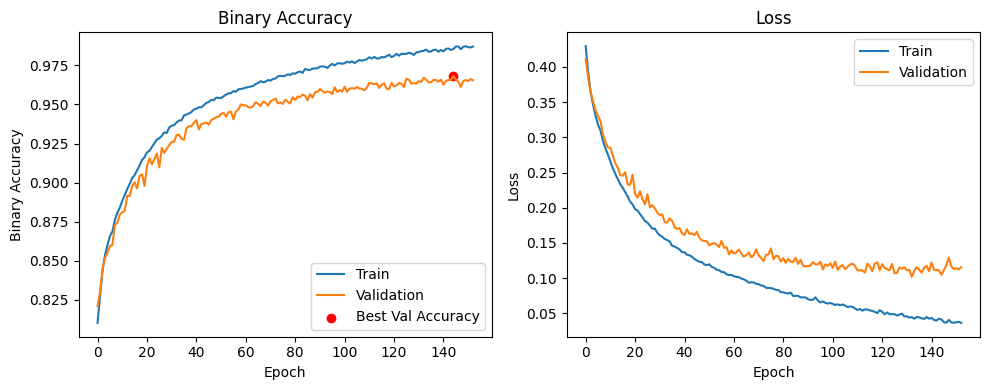

In [10]:
# History plot
log_df = pd.read_csv('training_model_mix.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Confusion matrix for validation and test sets
model.load_weights('best_model_mix.h5')

from sklearn.metrics import multilabel_confusion_matrix

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

# val_cm[i] is the confusion matrix for class i
#for i, category in enumerate(instrument_categories):
#    print(f"Confusion matrix for {category}:")
#    print(val_cm[i])

43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


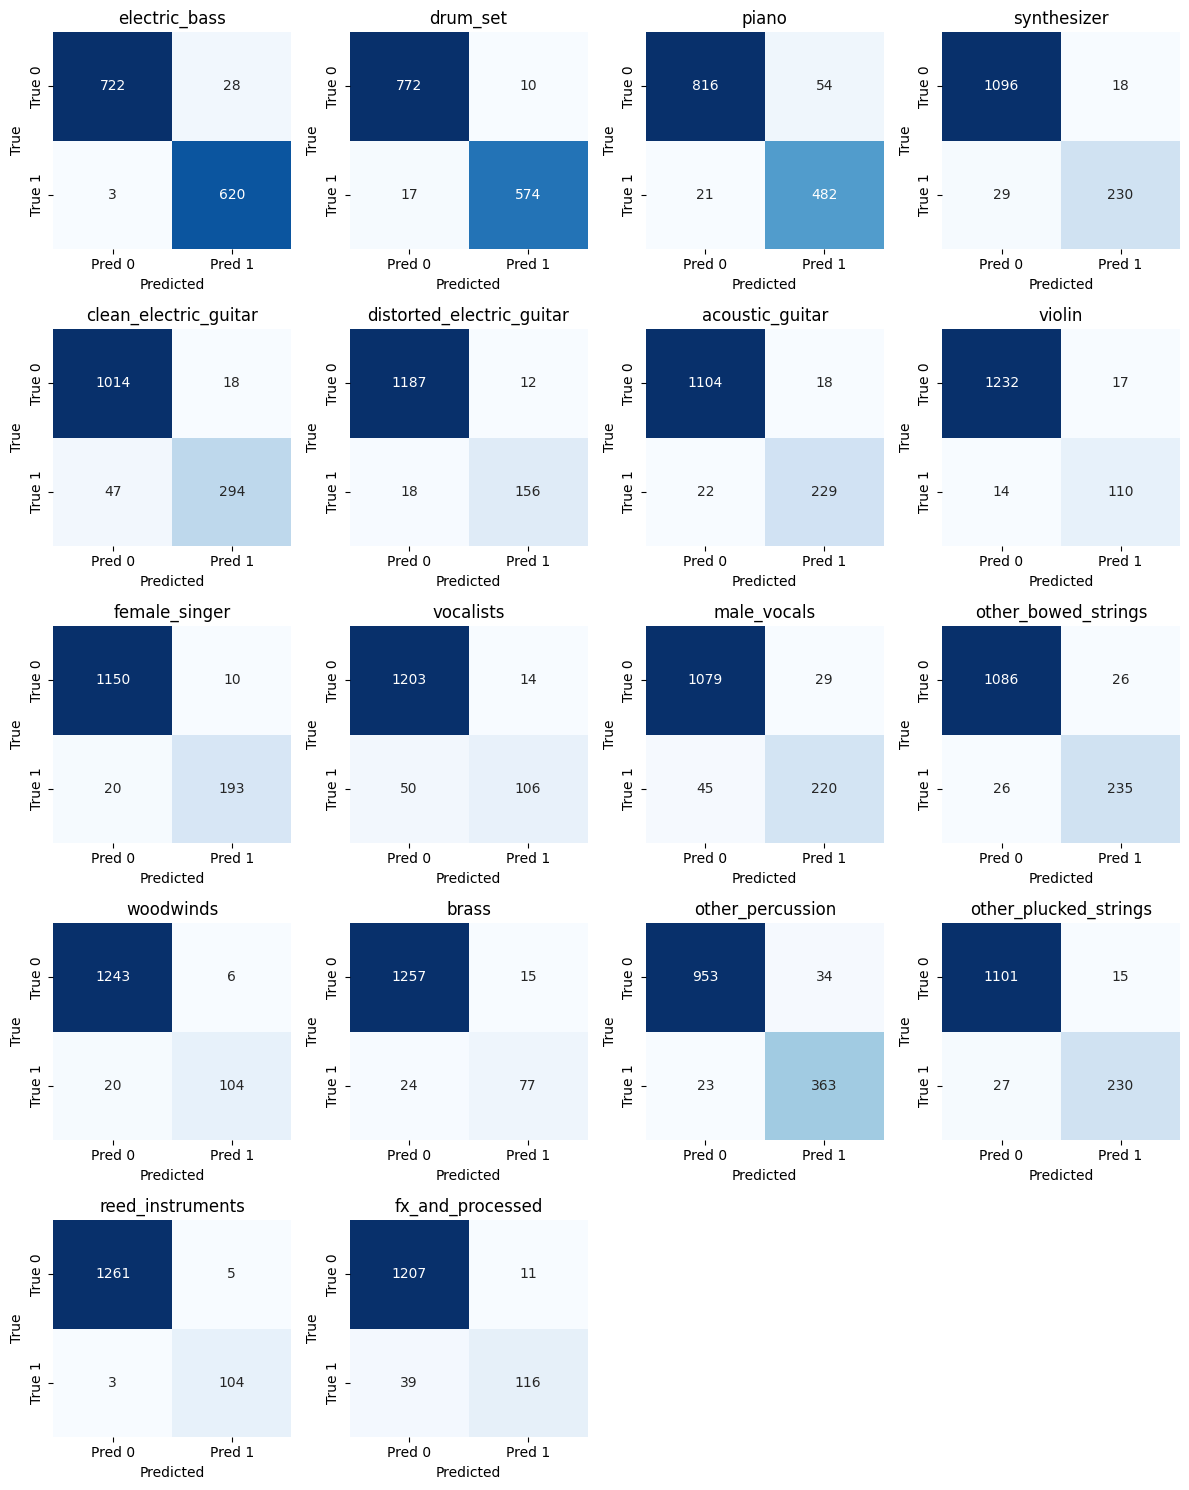

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

In [13]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98       623
           1       0.98      0.97      0.98       591
           2       0.90      0.96      0.93       503
           3       0.93      0.89      0.91       259
           4       0.94      0.86      0.90       341
           5       0.93      0.90      0.91       174
           6       0.93      0.91      0.92       251
           7       0.87      0.89      0.88       124
           8       0.95      0.91      0.93       213
           9       0.88      0.68      0.77       156
          10       0.88      0.83      0.86       265
          11       0.90      0.90      0.90       261
          12       0.95      0.84      0.89       124
          13       0.84      0.76      0.80       101
          14       0.91      0.94      0.93       386
          15       0.94      0.89      0.92       257
          16       0.95      0.97      0.96       107
          17       0.91    

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Model 2: reduced model, all 18 classes

In [9]:
input_shape = (96, 130, 1)
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'), 
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 130, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 130, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 65, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 65, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 65, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         1,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,274 (32.32 KB)

 Trainable params: 8,178 (31.95 KB)

 Non-trainable params: 96 (384.00 B)

In [11]:
# Callbacks for training
csv_logger = CSVLogger('training_model_mix_smaller.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=50)

model_name = 'best_model_mix_smaller.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - binary_accuracy: 0.7337 - loss: 0.5418
Epoch 1: val_binary_accuracy improved from -inf to 0.74209, saving model to best_model_mix_smaller.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - binary_accuracy: 0.7342 - loss: 0.5411 - val_binary_accuracy: 0.7421 - val_loss: 0.6041
Epoch 2/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - binary_accuracy: 0.8325 - loss: 0.3984
Epoch 2: val_binary_accuracy improved from 0.74209 to 0.76378, saving model to best_model_mix_smaller.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - binary_accuracy: 0.8325 - loss: 0.3983 - val_binary_accuracy: 0.7638 - val_loss: 0.5217
Epoch 3/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - binary_accuracy: 0.8435 - loss: 0.3691
Epoch 3: val_binary_accuracy improved from 0.76378 to 0.84596, saving model to best_model_mix_smaller.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 69ms/step - binary_accuracy: 0.8436 - loss: 0.3691 - val_binary_accuracy: 0.8460 - val_loss: 0.3886
Epoch 4/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.8534 - loss: 0.3467
Epoch 4: val_binary_accuracy improved from 0.84596 to 0.85583, saving model to best_model_mix_smaller.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.8534 - loss: 0.3467 - val_binary_accuracy: 0.8558 - val_loss: 0.3381
Epoch 5/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.8600 - loss: 0.3328
Epoch 5: val_binary_accuracy did not improve from 0.85583
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.8600 - loss: 0.3328 - val_binary_accuracy: 0.8371 - val_loss: 0.3871
Epoch 6/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - binary_accuracy: 0.8611 - loss: 0.3268
Epoch 6: val_binary_accuracy improved from 0.85583 to 0.85793, saving model to best_model_mix_smaller.h5


...

215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9310 - loss: 0.1691 - val_binary_accuracy: 0.9312 - val_loss: 0.1724
Epoch 83/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9290 - loss: 0.1694
Epoch 83: val_binary_accuracy improved from 0.93117 to 0.93376, saving model to best_model_mix_smaller.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9290 - loss: 0.1694 - val_binary_accuracy: 0.9338 - val_loss: 0.1643
Epoch 84/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - binary_accuracy: 0.9315 - loss: 0.1664
Epoch 84: val_binary_accuracy did not improve from 0.93376
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9315 - loss: 0.1664 - val_binary_accuracy: 0.8972 - val_loss: 0.2835
Epoch 85/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9291 - loss: 0.1715
Epoch 85: val_binary_accuracy did not improve from 0.93376
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9291 - loss: 0.1715 - val_binary_accuracy: 0.9298 - val_loss: 0.1708
Epoch 86/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9280 - loss: 0.1723
Epoch 86: val_binary_accuracy did not improve from 0.93376
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9281 - loss: 0.1723 - val_binary_accuracy: 0.9194 - val_loss: 0.2054
Epo

215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 69ms/step - binary_accuracy: 0.9345 - loss: 0.1565 - val_binary_accuracy: 0.9399 - val_loss: 0.1491
Epoch 131/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9365 - loss: 0.1508
Epoch 131: val_binary_accuracy did not improve from 0.93987
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9365 - loss: 0.1508 - val_binary_accuracy: 0.9304 - val_loss: 0.1789
Epoch 132/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9357 - loss: 0.1570
Epoch 132: val_binary_accuracy did not improve from 0.93987
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9357 - loss: 0.1570 - val_binary_accuracy: 0.9189 - val_loss: 0.2071
Epoch 133/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9370 - loss: 0.1560
Epoch 133: val_binary_accuracy did not improve from 0.93987
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9370 - loss: 0.1560 - val_binary_accuracy: 0.9294 - val_loss: 0.17

215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 69ms/step - binary_accuracy: 0.9381 - loss: 0.1482 - val_binary_accuracy: 0.9399 - val_loss: 0.1472
Epoch 174/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9402 - loss: 0.1450
Epoch 174: val_binary_accuracy did not improve from 0.93991
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9402 - loss: 0.1450 - val_binary_accuracy: 0.9320 - val_loss: 0.1724
Epoch 175/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9391 - loss: 0.1469
Epoch 175: val_binary_accuracy did not improve from 0.93991
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9391 - loss: 0.1470 - val_binary_accuracy: 0.9171 - val_loss: 0.2525
Epoch 176/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9378 - loss: 0.1484
Epoch 176: val_binary_accuracy did not improve from 0.93991
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9379 - loss: 0.1483 - val_binary_accuracy: 0.9317 - val_loss: 0.18

215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9380 - loss: 0.1471 - val_binary_accuracy: 0.9404 - val_loss: 0.1545
Epoch 180/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9381 - loss: 0.1481
Epoch 180: val_binary_accuracy did not improve from 0.94044
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9381 - loss: 0.1481 - val_binary_accuracy: 0.9323 - val_loss: 0.1817
Epoch 181/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9370 - loss: 0.1476
Epoch 181: val_binary_accuracy did not improve from 0.94044
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9370 - loss: 0.1476 - val_binary_accuracy: 0.9353 - val_loss: 0.1642
Epoch 182/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9378 - loss: 0.1483
Epoch 182: val_binary_accuracy did not improve from 0.94044
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9378 - loss: 0.1483 - val_binary_accuracy: 0.9355 - val_loss: 0.16

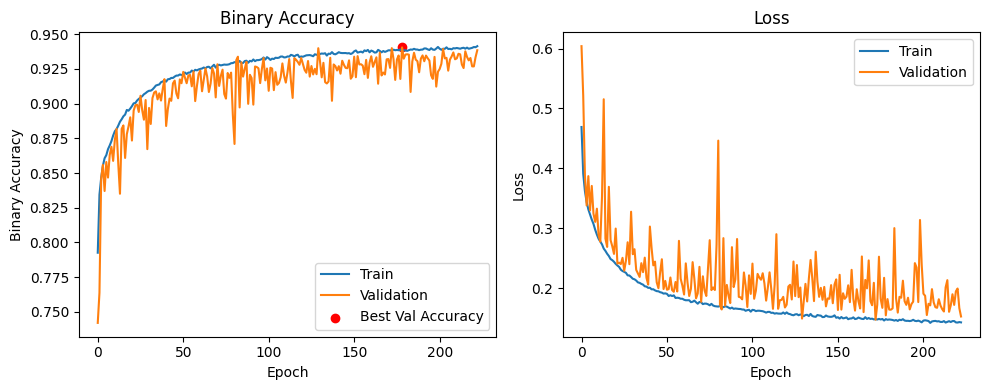

In [12]:
# History plot
log_df = pd.read_csv('training_model_mix_smaller.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Confusion matrix for validation and test sets
model.load_weights('best_model_mix_smaller.h5')

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


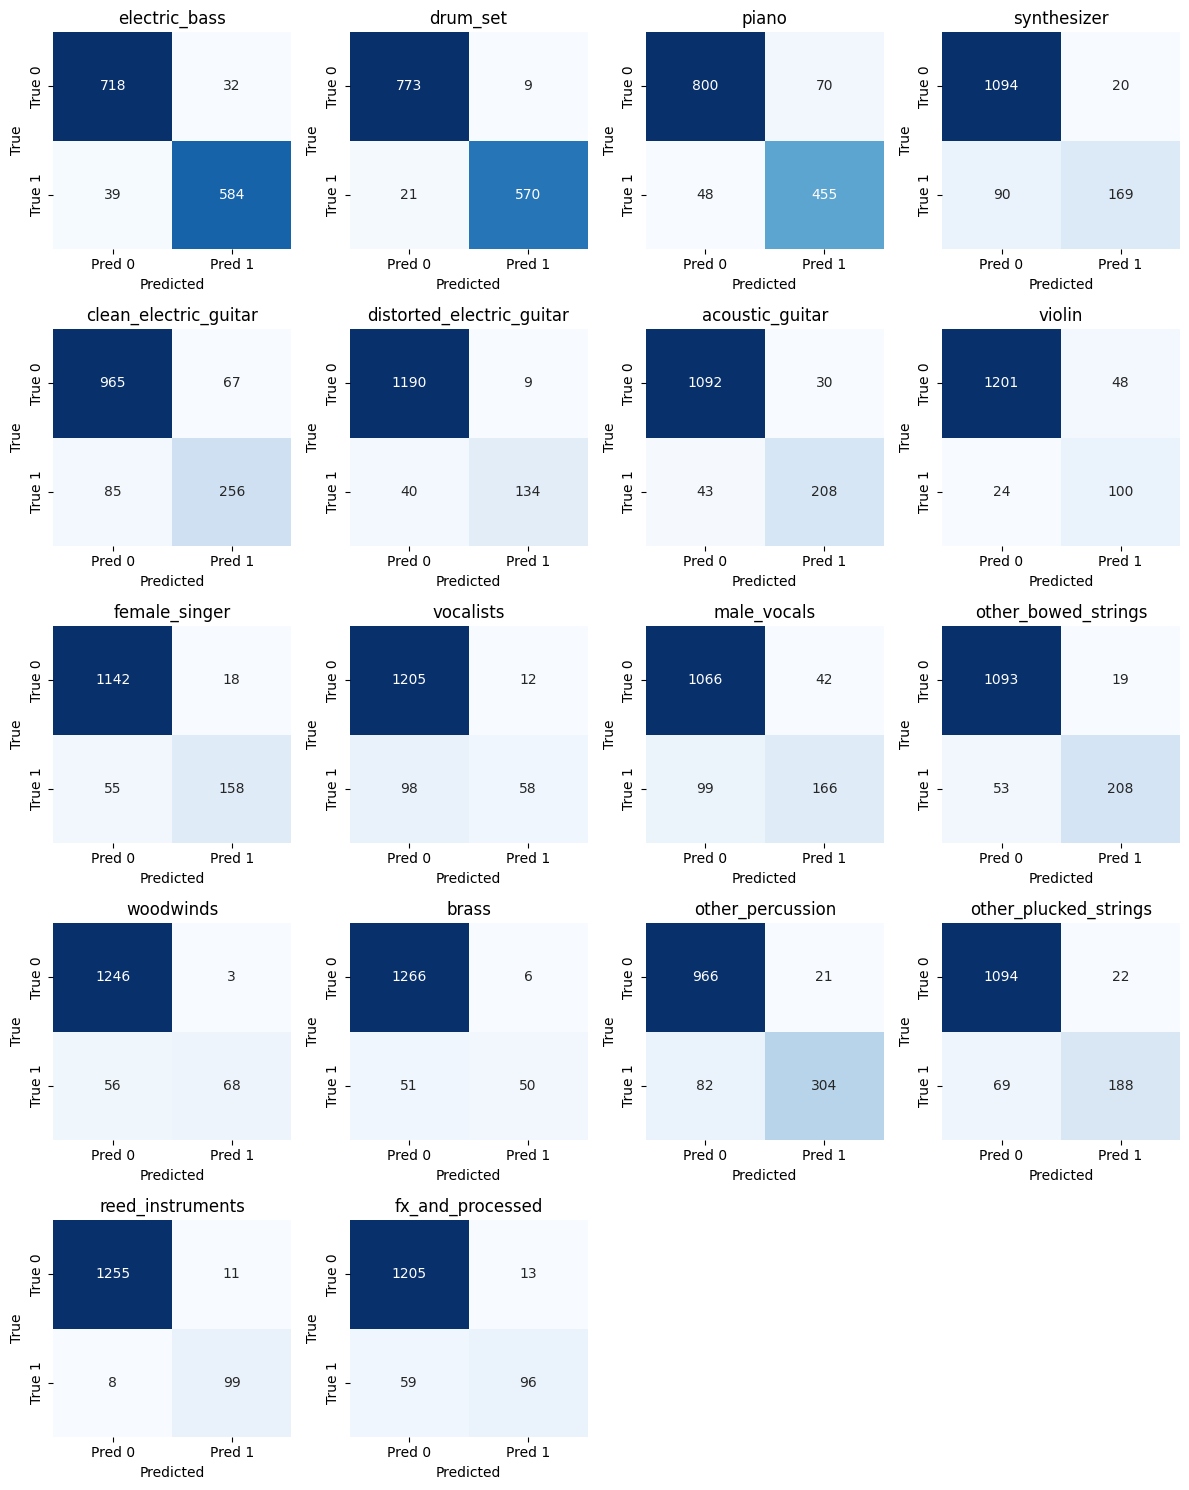

In [14]:
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

# Model 3: from CQT to MEL

In [15]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    mel_features, labels, test_size=0.1, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

print(f"Loaded data: {mel_features.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)


Loaded data: (9154, 96, 130)


In [16]:
input_shape = (96, 130, 1)
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'), 
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 96, 130, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 96, 130, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 48, 65, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 65, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 48, 65, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 18)             │         1,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,274 (32.32 KB)

 Trainable params: 8,178 (31.95 KB)

 Non-trainable params: 96 (384.00 B)

In [17]:
# Callbacks for training
csv_logger = CSVLogger('training_model_mix_mel.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=50)

model_name = 'best_model_mix_mel.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - binary_accuracy: 0.7663 - loss: 0.5012
Epoch 1: val_binary_accuracy improved from -inf to 0.80396, saving model to best_model_mix_mel.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - binary_accuracy: 0.7667 - loss: 0.5006 - val_binary_accuracy: 0.8040 - val_loss: 0.5900
Epoch 2/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - binary_accuracy: 0.8367 - loss: 0.3795
Epoch 2: val_binary_accuracy improved from 0.80396 to 0.83997, saving model to best_model_mix_mel.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 69ms/step - binary_accuracy: 0.8367 - loss: 0.3794 - val_binary_accuracy: 0.8400 - val_loss: 0.4502
Epoch 3/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.8490 - loss: 0.3413
Epoch 3: val_binary_accuracy improved from 0.83997 to 0.84454, saving model to best_model_mix_mel.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.8490 - loss: 0.3413 - val_binary_accuracy: 0.8445 - val_loss: 0.3463
Epoch 4/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.8574 - loss: 0.3237
Epoch 4: val_binary_accuracy improved from 0.84454 to 0.85988, saving model to best_model_mix_mel.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.8574 - loss: 0.3236 - val_binary_accuracy: 0.8599 - val_loss: 0.3056
Epoch 5/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - binary_accuracy: 0.8654 - loss: 0.3025
Epoch 5: val_binary_accuracy did not improve from 0.85988
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 69ms/step - binary_accuracy: 0.8654 - loss: 0.3025 - val_binary_accuracy: 0.8530 - val_loss: 0.3409
Epoch 6/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.8699 - loss: 0.2943
Epoch 6: val_binary_accuracy improved from 0.85988 to 0.86352, saving model to best_model_mix_mel.h5


...

215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9431 - loss: 0.1348 - val_binary_accuracy: 0.9503 - val_loss: 0.1271
Epoch 192/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9443 - loss: 0.1343
Epoch 192: val_binary_accuracy did not improve from 0.95031
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9443 - loss: 0.1343 - val_binary_accuracy: 0.9461 - val_loss: 0.1416
Epoch 193/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9451 - loss: 0.1323
Epoch 193: val_binary_accuracy did not improve from 0.95031
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9451 - loss: 0.1323 - val_binary_accuracy: 0.9413 - val_loss: 0.1500
Epoch 194/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9449 - loss: 0.1321
Epoch 194: val_binary_accuracy did not improve from 0.95031
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9449 - loss: 0.1321 - val_binary_accuracy: 0.9502 - val_loss: 0.12

215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 69ms/step - binary_accuracy: 0.9430 - loss: 0.1317 - val_binary_accuracy: 0.9505 - val_loss: 0.1248
Epoch 219/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9461 - loss: 0.1295
Epoch 219: val_binary_accuracy did not improve from 0.95051
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9461 - loss: 0.1296 - val_binary_accuracy: 0.9466 - val_loss: 0.1380
Epoch 220/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9453 - loss: 0.1299
Epoch 220: val_binary_accuracy did not improve from 0.95051
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9453 - loss: 0.1299 - val_binary_accuracy: 0.9313 - val_loss: 0.1809
Epoch 221/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9463 - loss: 0.1286
Epoch 221: val_binary_accuracy did not improve from 0.95051
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9463 - loss: 0.1286 - val_binary_accuracy: 0.9361 - val_loss: 0.17

215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9447 - loss: 0.1322 - val_binary_accuracy: 0.9506 - val_loss: 0.1273
Epoch 226/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9447 - loss: 0.1312
Epoch 226: val_binary_accuracy improved from 0.95064 to 0.95092, saving model to best_model_mix_mel.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9447 - loss: 0.1312 - val_binary_accuracy: 0.9509 - val_loss: 0.1250
Epoch 227/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9448 - loss: 0.1335
Epoch 227: val_binary_accuracy did not improve from 0.95092
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9448 - loss: 0.1335 - val_binary_accuracy: 0.9426 - val_loss: 0.1490
Epoch 228/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9452 - loss: 0.1300
Epoch 228: val_binary_accuracy did not improve from 0.95092
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9452 - loss: 0.1300 - val_binary_accuracy: 0.9423 - val_loss: 0.1464
Epoch 229/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9435 - loss: 0.1357
Epoch 229: val_binary_accuracy did not improve from 0.95092
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9436 - loss: 0.1357 - val_binary_accuracy: 0.9429 - val_loss: 0.14

215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 69ms/step - binary_accuracy: 0.9448 - loss: 0.1305 - val_binary_accuracy: 0.9517 - val_loss: 0.1239
Epoch 251/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9459 - loss: 0.1297
Epoch 251: val_binary_accuracy did not improve from 0.95169
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9459 - loss: 0.1297 - val_binary_accuracy: 0.9413 - val_loss: 0.1576
Epoch 252/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9456 - loss: 0.1290
Epoch 252: val_binary_accuracy did not improve from 0.95169
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9456 - loss: 0.1290 - val_binary_accuracy: 0.9453 - val_loss: 0.1425
Epoch 253/300
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - binary_accuracy: 0.9458 - loss: 0.1284
Epoch 253: val_binary_accuracy did not improve from 0.95169
215/215 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - binary_accuracy: 0.9458 - loss: 0.1285 - val_binary_accuracy: 0.9500 - val_loss: 0.12

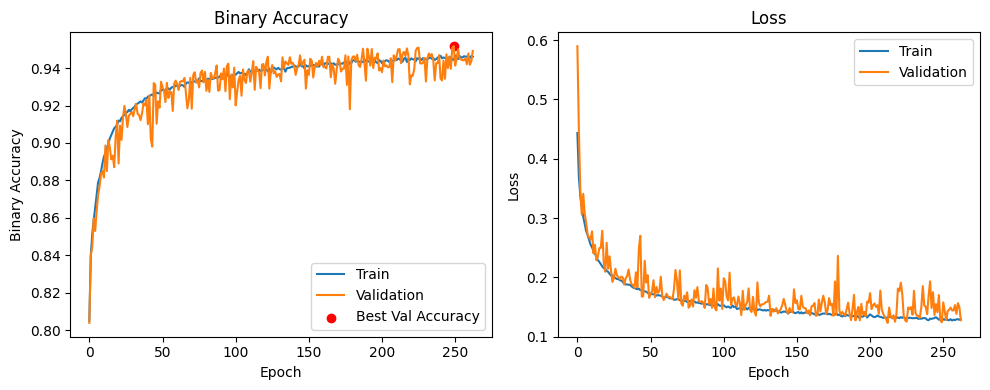

In [18]:
# History plot
log_df = pd.read_csv('training_model_mix_mel.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# Confusion matrix for validation and test sets
model.load_weights('best_model_mix_mel.h5')

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


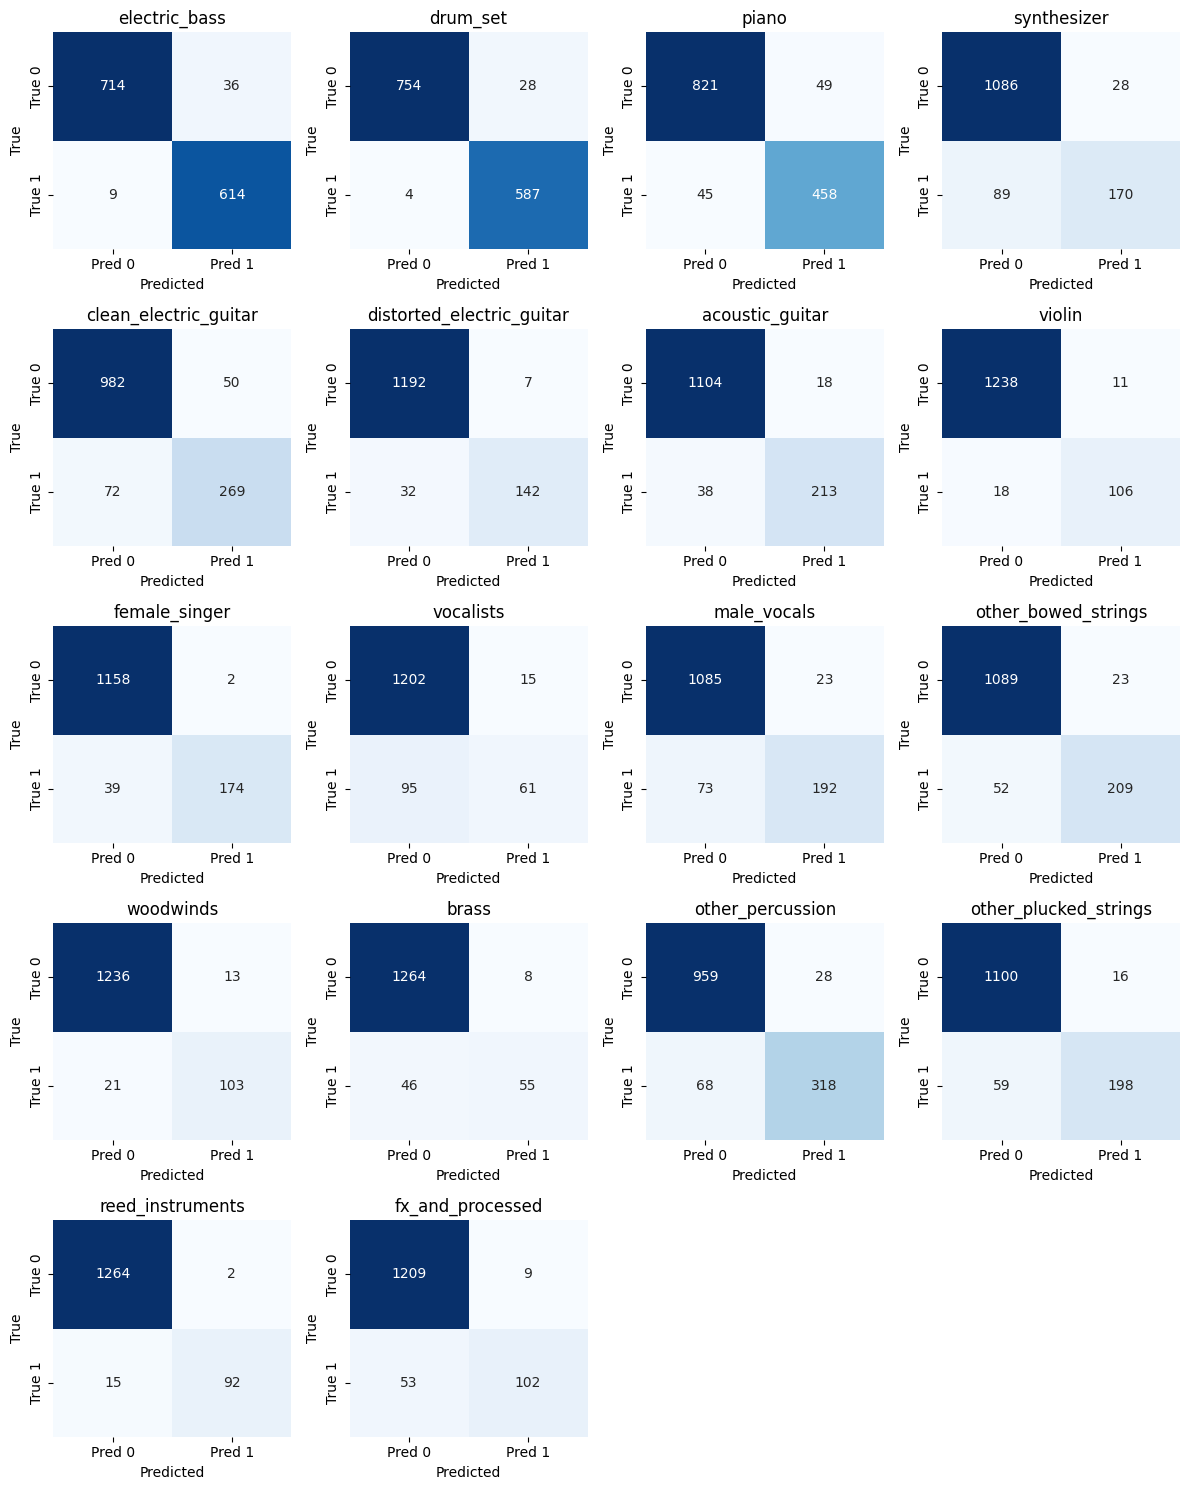

In [20]:
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

# Eliminating classes

In [ ]:
# Cargar datos
X = np.load("extracted_mix_features/all_cqts.npy")
y = np.load("extracted_mix_features/all_labels.npy")

# Clases a eliminar (por ejemplo: [3, 17])
classes_to_remove = [3, 17]

# Eliminar columnas de esas clases en las etiquetas
y_filtered = np.delete(y, classes_to_remove, axis=1)

# Obtener el orden original de etiquetas desde category_to_idx
idx_to_category = {v: k for k, v in category_to_idx.items()}
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Eliminar etiquetas del listado ordenado
for idx in sorted(classes_to_remove, reverse=True):
    del ordered_labels[idx]

# Verificación rápida
print(f"Shape original de y: {y.shape}")
print(f"Shape después de eliminar clases: {y_filtered.shape}")
print(f"Número de categorías actual: {len(ordered_labels)}")

Shape original de y: (9154, 18)
Shape después de eliminar clases: (9154, 16)
Número de categorías actual: 16



Distribución de clases en el dataset filtrado:
  electric_bass: 4100 muestras (44.8%)
  drum_set: 3884 muestras (42.4%)
  piano: 3395 muestras (37.1%)
  other_percussion: 2597 muestras (28.4%)
  clean_electric_guitar: 2402 muestras (26.2%)
  other_plucked_strings: 1767 muestras (19.3%)
  other_bowed_strings: 1760 muestras (19.2%)
  male_vocals: 1733 muestras (18.9%)
  acoustic_guitar: 1526 muestras (16.7%)
  female_singer: 1330 muestras (14.5%)
  distorted_electric_guitar: 1097 muestras (12.0%)
  vocalists: 851 muestras (9.3%)
  violin: 785 muestras (8.6%)
  woodwinds: 750 muestras (8.2%)
  reed_instruments: 750 muestras (8.2%)
  brass: 653 muestras (7.1%)


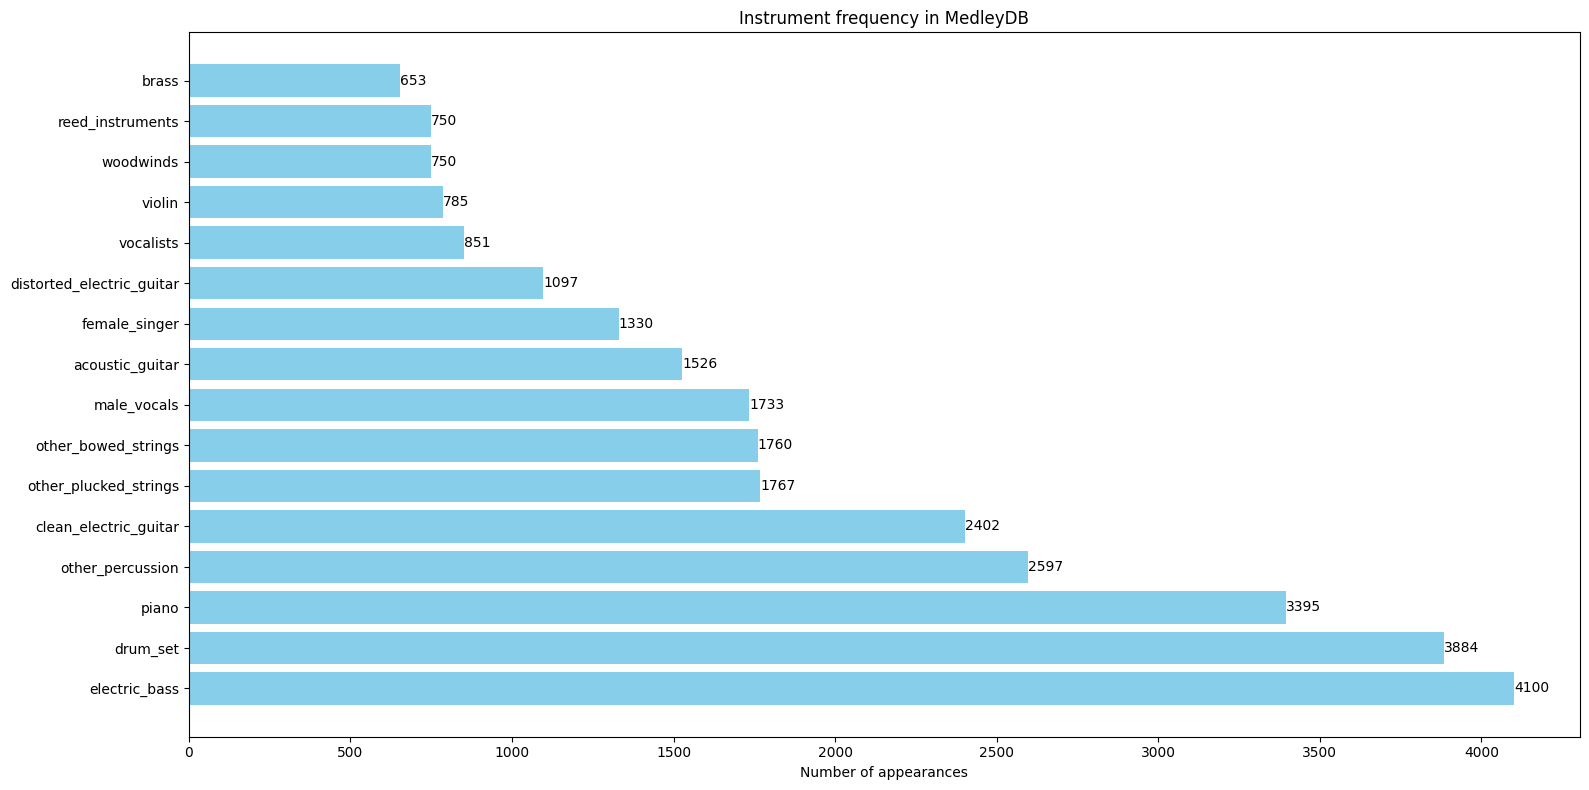


Dimensiones del dataset:
  X: (9154, 96, 130)
  y filtrado (multi-hot): (9154, 16)
  Total de muestras: 9154
  Número de categorías actuales: 16


In [15]:
# Sumar cuántas veces aparece cada clase (suma por columnas)
class_counts = np.sum(y_filtered, axis=0)

# Crear diccionario {nombre_categoria: cantidad}
category_counts = {label: int(count) for label, count in zip(ordered_labels, class_counts)}

# Mostrar la distribución
print("\nDistribución de clases en el dataset filtrado:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} muestras ({count / len(y_filtered) * 100:.1f}%)")

# Graficar histograma
plot_instrument_histogram(category_counts, top_n=len(ordered_labels))

# Resumen general
print(f"\nDimensiones del dataset:")
print(f"  X: {X.shape}")
print(f"  y filtrado (multi-hot): {y_filtered.shape}")
print(f"  Total de muestras: {len(y_filtered)}")
print(f"  Número de categorías actuales: {len(ordered_labels)}")


In [16]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y_filtered, test_size=0.1, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

print(f"Loaded data: {cqt_features.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

Loaded data: (9154, 96, 130)


# Model 4: sharing architecture with Stems, case 64, already reduced

In [ ]:
input_shape = (96, 130, 1)
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(96, 130, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'), 
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 94, 128, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 47, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 45, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 22, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 20, 29, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,968 (398.31 KB)

 Trainable params: 101,968 (398.31 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Callbacks for training
csv_logger = CSVLogger('training_model_mix_2.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=70)

model_name = 'best_model_mix_2.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=400,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.7953 - loss: 0.4803
Epoch 1: val_binary_accuracy improved from -inf to 0.81341, saving model to best_model_mix_2.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - binary_accuracy: 0.7954 - loss: 0.4799 - val_binary_accuracy: 0.8134 - val_loss: 0.4229
Epoch 2/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.8196 - loss: 0.4065
Epoch 2: val_binary_accuracy improved from 0.81341 to 0.82179, saving model to best_model_mix_2.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.8196 - loss: 0.4064 - val_binary_accuracy: 0.8218 - val_loss: 0.3946
Epoch 3/400
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.8301 - loss: 0.3825
Epoch 3: val_binary_accuracy improved from 0.82179 to 0.83335, saving model to best_model_mix_2.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.8301 - loss: 0.3825 - val_binary_accuracy: 0.8333 - val_loss: 0.3774
Epoch 4/400
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.8438 - loss: 0.3622
Epoch 4: val_binary_accuracy improved from 0.83335 to 0.84600, saving model to best_model_mix_2.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.8438 - loss: 0.3622 - val_binary_accuracy: 0.8460 - val_loss: 0.3508
Epoch 5/400
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.8559 - loss: 0.3346
Epoch 5: val_binary_accuracy improved from 0.84600 to 0.85383, saving model to best_model_mix_2.h5


...

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - binary_accuracy: 0.9916 - loss: 0.0224 - val_binary_accuracy: 0.9717 - val_loss: 0.1028
Epoch 164/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - binary_accuracy: 0.9926 - loss: 0.0208
Epoch 164: val_binary_accuracy did not improve from 0.97173
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - binary_accuracy: 0.9926 - loss: 0.0209 - val_binary_accuracy: 0.9676 - val_loss: 0.1140
Epoch 165/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9924 - loss: 0.0219
Epoch 165: val_binary_accuracy did not improve from 0.97173
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9924 - loss: 0.0219 - val_binary_accuracy: 0.9690 - val_loss: 0.1107
Epoch 166/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - binary_accuracy: 0.9925 - loss: 0.0216
Epoch 166: val_binary_accuracy did not improve from 0.97173
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - binary_accuracy: 0.9925 - loss: 0.0216 - val_binary_accuracy: 0.9673 - val_loss: 0.11

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step - binary_accuracy: 0.9905 - loss: 0.0265 - val_binary_accuracy: 0.9727 - val_loss: 0.1047
Epoch 170/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9933 - loss: 0.0189
Epoch 170: val_binary_accuracy did not improve from 0.97273
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9933 - loss: 0.0189 - val_binary_accuracy: 0.9714 - val_loss: 0.1081
Epoch 171/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9925 - loss: 0.0202
Epoch 171: val_binary_accuracy did not improve from 0.97273
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9925 - loss: 0.0202 - val_binary_accuracy: 0.9685 - val_loss: 0.1234
Epoch 172/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9923 - loss: 0.0208
Epoch 172: val_binary_accuracy did not improve from 0.97273
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9923 - loss: 0.0208 - val_binary_accuracy: 0.9679 - val_loss: 0.11

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9946 - loss: 0.0160 - val_binary_accuracy: 0.9730 - val_loss: 0.1047
Epoch 185/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9932 - loss: 0.0201
Epoch 185: val_binary_accuracy did not improve from 0.97296
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9932 - loss: 0.0201 - val_binary_accuracy: 0.9718 - val_loss: 0.1082
Epoch 186/400
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9932 - loss: 0.0190
Epoch 186: val_binary_accuracy did not improve from 0.97296
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9932 - loss: 0.0190 - val_binary_accuracy: 0.9699 - val_loss: 0.1211
Epoch 187/400
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9948 - loss: 0.0154
Epoch 187: val_binary_accuracy did not improve from 0.97296
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9948 - loss: 0.0154 - val_binary_accuracy: 0.9715 - val_loss: 0.11

215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9938 - loss: 0.0170 - val_binary_accuracy: 0.9732 - val_loss: 0.1111
Epoch 202/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9946 - loss: 0.0148
Epoch 202: val_binary_accuracy did not improve from 0.97319
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9946 - loss: 0.0148 - val_binary_accuracy: 0.9700 - val_loss: 0.1291
Epoch 203/400
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9914 - loss: 0.0247
Epoch 203: val_binary_accuracy did not improve from 0.97319
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9914 - loss: 0.0247 - val_binary_accuracy: 0.9724 - val_loss: 0.1170
Epoch 204/400
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9948 - loss: 0.0143
Epoch 204: val_binary_accuracy improved from 0.97319 to 0.97342, saving model to best_model_mix_2.h5


215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - binary_accuracy: 0.9948 - loss: 0.0143 - val_binary_accuracy: 0.9734 - val_loss: 0.1131
Epoch 205/400
215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - binary_accuracy: 0.9957 - loss: 0.0130
Epoch 205: val_binary_accuracy did not improve from 0.97342
215/215 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - binary_accuracy: 0.9957 - loss: 0.0130 - val_binary_accuracy: 0.9691 - val_loss: 0.1312
Epoch 206/400
214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - binary_accuracy: 0.9934 - loss: 0.0177
Epoch 206: val_binary_accuracy did not improve from 0.97342
215/215 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - binary_accuracy: 0.9934 - loss: 0.0177 - val_binary_accuracy: 0.9713 - val_loss: 0.1174


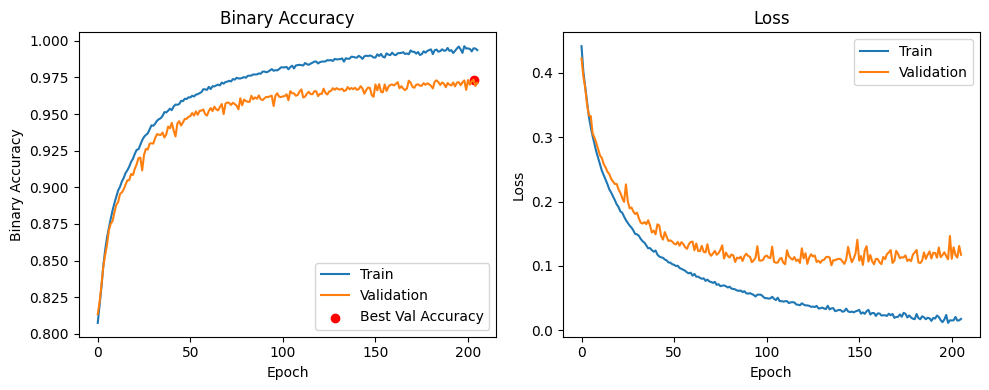

In [19]:
# History plot
log_df = pd.read_csv('training_model_mix_2.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Confusion matrix for validation and test sets
model.load_weights('best_model_mix_2.h5')

from sklearn.metrics import multilabel_confusion_matrix

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

# val_cm[i] is the confusion matrix for class i
#for i, category in enumerate(instrument_categories):
#    print(f"Confusion matrix for {category}:")
#    print(val_cm[i])

43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


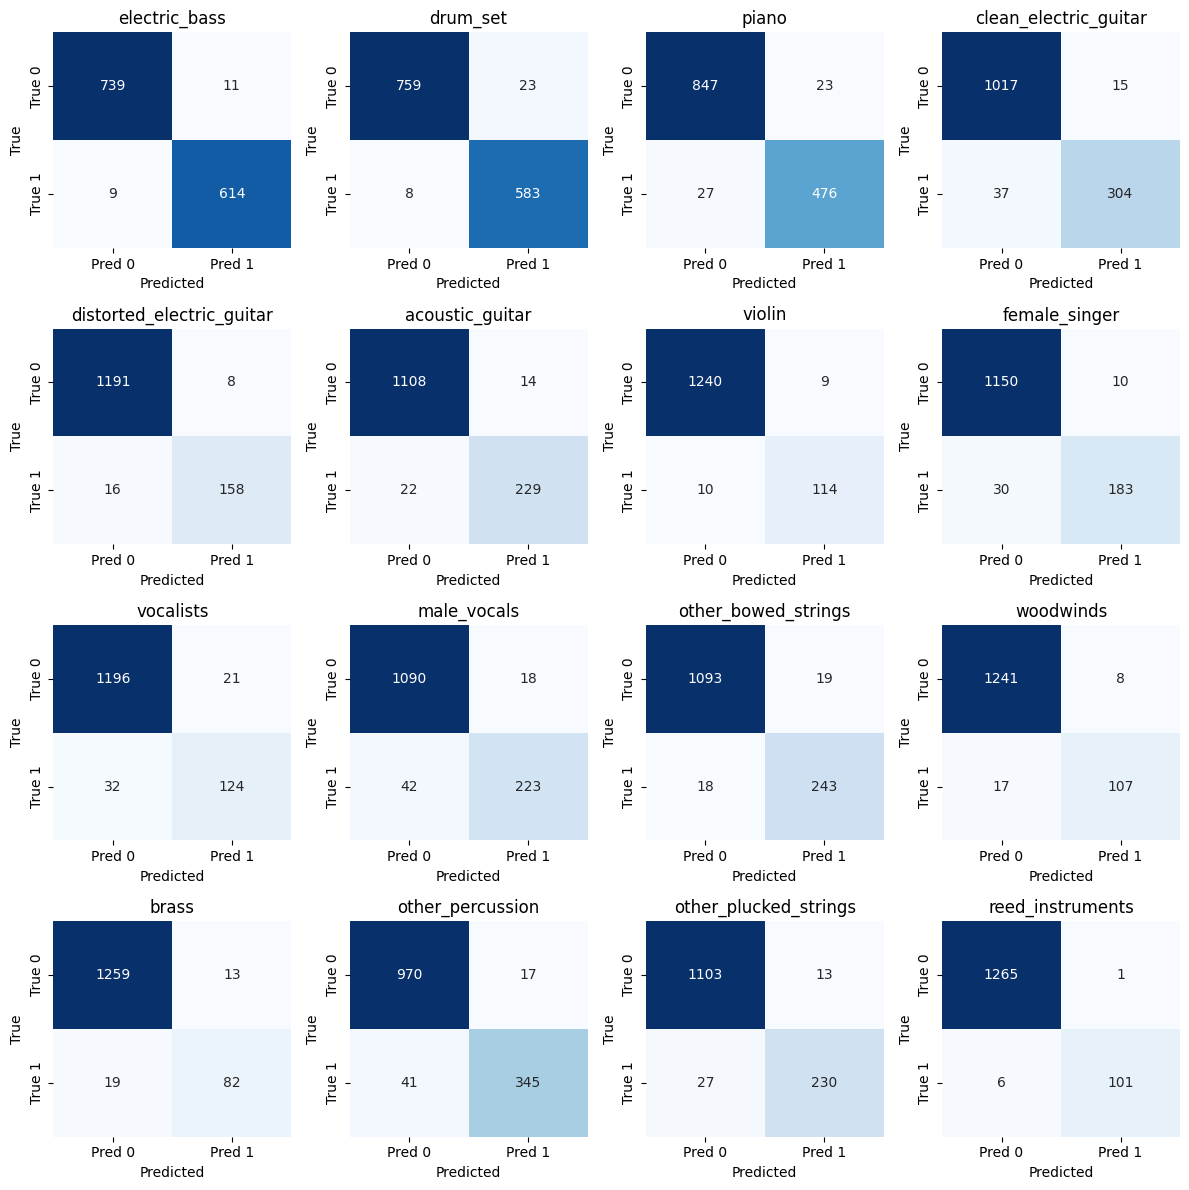

In [ ]:
# Remove the same classes from instrument_categories
instrument_categories_2 = [cat for i, cat in enumerate(instrument_categories) 
                       if i not in classes_to_remove]

num_classes = len(instrument_categories_2)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories_2):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

In [24]:
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       623
           1       0.96      0.99      0.97       591
           2       0.95      0.95      0.95       503
           3       0.95      0.89      0.92       341
           4       0.95      0.91      0.93       174
           5       0.94      0.91      0.93       251
           6       0.93      0.92      0.92       124
           7       0.95      0.86      0.90       213
           8       0.86      0.79      0.82       156
           9       0.93      0.84      0.88       265
          10       0.93      0.93      0.93       261
          11       0.93      0.86      0.90       124
          12       0.86      0.81      0.84       101
          13       0.95      0.89      0.92       386
          14       0.95      0.89      0.92       257
          15       0.99      0.94      0.97       107

   micro avg       0.95      0.92      0.93      4477
   macro avg       0.94   

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(resul